In [7]:
from scr import mutation_estimation

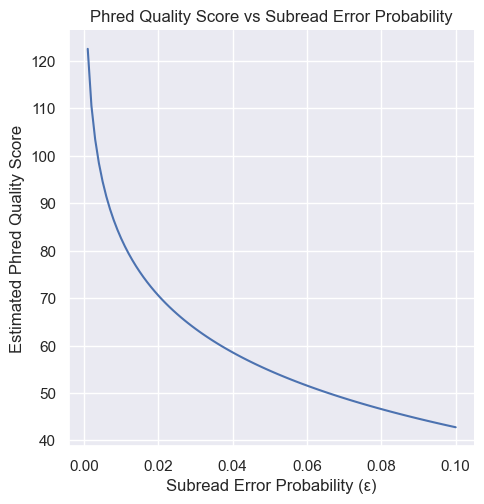

In [8]:
mutation_estimation.plot_phred_eps_dependency(0.001, 0.1, 100, 6)

### Cosmic Mutations

In [1]:
import pandas as pd
import os

In [2]:
mutations = pd.read_csv("data/thyroid/nanoseq_mutation_data.tsv", sep="\t")
genome_tri_prop_path = "data/h19_tri32.csv"
seq_path = "data/thyroid/tnfrsf14.fasta"

Length of target sequence: 9744


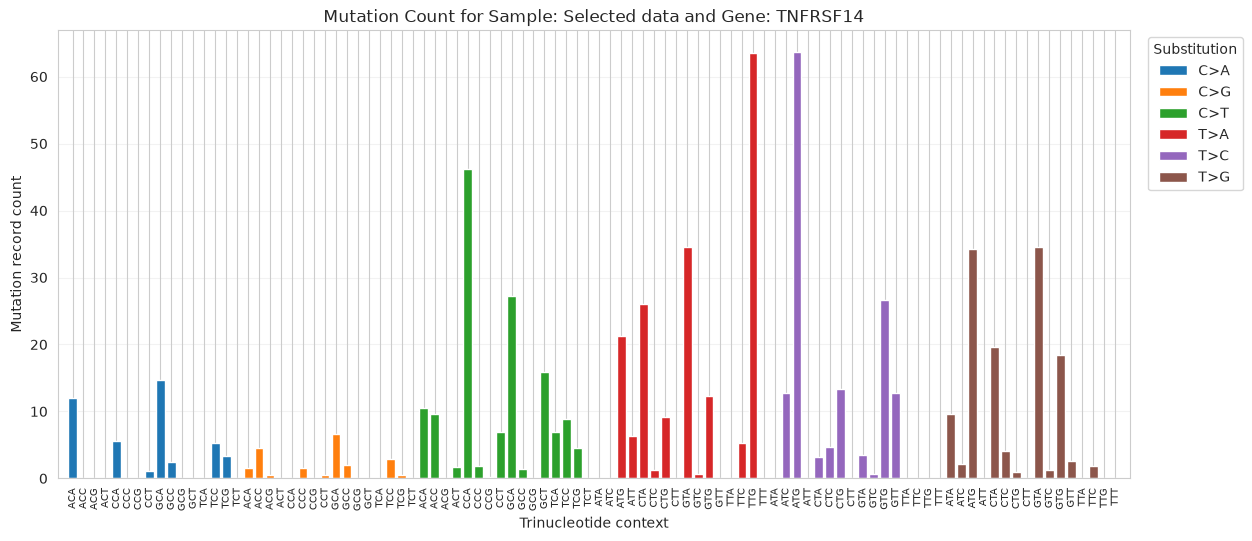

In [3]:
from scr.sbs96_computation import (
    add_sample_metadata,
    build_sbs96_matrix,
    select_mutations,
    tri_correct,
    plot_sbs96_matrix
)

mutations = add_sample_metadata(mutations)

selected = select_mutations(
    mutations,
    # donor_biopsy_id="PD63118b",
    gene="TNFRSF14",
)

matrix = build_sbs96_matrix(selected)
corr_matrix = tri_correct(mut_matrix=matrix, 
                          genome_tri_prop_path=genome_tri_prop_path,
                          seq_path=seq_path)

sbs96_matrix_ax = plot_sbs96_matrix(corr_matrix)

In [4]:
selected

,sampleID,paper_id,chr,pos,ref,mut,type,tri,times_called,duplex_vaf,...,ref3_cod,mut3_cod,aachange,ntchange,codonsub,impact,pid,donor_biopsy_id,tds,assay
248,PD63118b_tds0001_exome_2,H1,1,2488104,A,C,snv,ATG>G,1,0.006173,...,CAT,CCT,M1L,A1C,ATG>CTG,Missense,ENSP00000347948,PD63118b,tds0001,exome_2
249,PD63118b_tds0001_exome_2,H1,1,2488105,T,A,snv,ATG>A,1,0.005882,...,ATG,AAG,M1K,T2A,ATG>AAG,Missense,ENSP00000347948,PD63118b,tds0001,exome_2
250,PD63118b_tds0001_exome_2,H1,1,2488105,T,C,snv,ATG>C,2,0.011765,...,ATG,ACG,M1T,T2C,ATG>ACG,Missense,ENSP00000347948,PD63118b,tds0001,exome_2
251,PD63118b_tds0001_exome_2,H1,1,2488106,G,A,snv,CCA>T,2,0.011628,...,TGG,TAG,M1I,G3A,ATG>ATA,Missense,ENSP00000347948,PD63118b,tds0001,exome_2
252,PD63118b_tds0001_exome_2,H1,1,2488106,G,T,snv,CCA>A,1,0.005814,...,TGG,TTG,M1I,G3T,ATG>ATT,Missense,ENSP00000347948,PD63118b,tds0001,exome_2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211523,PD66884b_tds0002_targeted,H9,1,2493111,G,A,snv,CCT>T,1,0.003559,...,AGG,AAG,.,.,.,Essential_Splice,ENSP00000347948,PD66884b,tds0002,targeted
211524,PD66884b_tds0002_targeted,H9,1,2494337,T,A,snv,GTA>A,1,0.001364,...,GTA,GAA,.,.,.,Essential_Splice,ENSP00000347948,PD66884b,tds0002,targeted
214620,PD66884b_tds0004_targeted,H9,1,2488138,G,A,snv,CCA>T,1,0.001692,...,TGG,TAG,W12*,G35A,TGG>TAG,Nonsense,ENSP00000347948,PD66884b,tds0004,targeted
214621,PD66884b_tds0004_targeted,H9,1,2489881,G,C,snv,ACA>G,1,0.001681,...,TGT,TCT,C93S,G278C,TGT>TCT,Missense,ENSP00000347948,PD66884b,tds0004,targeted


In [5]:
matrix

,sub,tri,count
0,C>A,ACA,8
1,C>A,ACC,0
2,C>A,ACG,0
3,C>A,ACT,0
4,C>A,CCA,10
...,...,...,...
91,T>G,GTT,1
92,T>G,TTA,0
93,T>G,TTC,1
94,T>G,TTG,0


### Test of EM algorithm

In [6]:
from scr.signature_estimation import em_algorithm, em_visualization, signatures_visualization

In [7]:
cosmic_path = "data/COSMIC_v3.5_SBS_GRCh37.txt"

In [8]:
new_signature_prop, q_function_values, expected_counts_per_signature, normalized_mutation_df = em_algorithm(corr_matrix, cosmic_path, signature_prop=None, max_iter=100, tol=1e-5)

In [9]:
new_signature_prop

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.02833534,
       0.        , 0.01551364, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.03181563,
       0.        , 0.        , 0.        , 0.27375222, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.06520118, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.12327669, 0.        , 0.        ,
       0.        , 0.        , 0.00421652, 0.        , 0.        ,
       0.00260809, 0.        , 0.        , 0.18273737, 0.0578539 ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.01112233, 0.        , 0.        , 0.        , 0.     

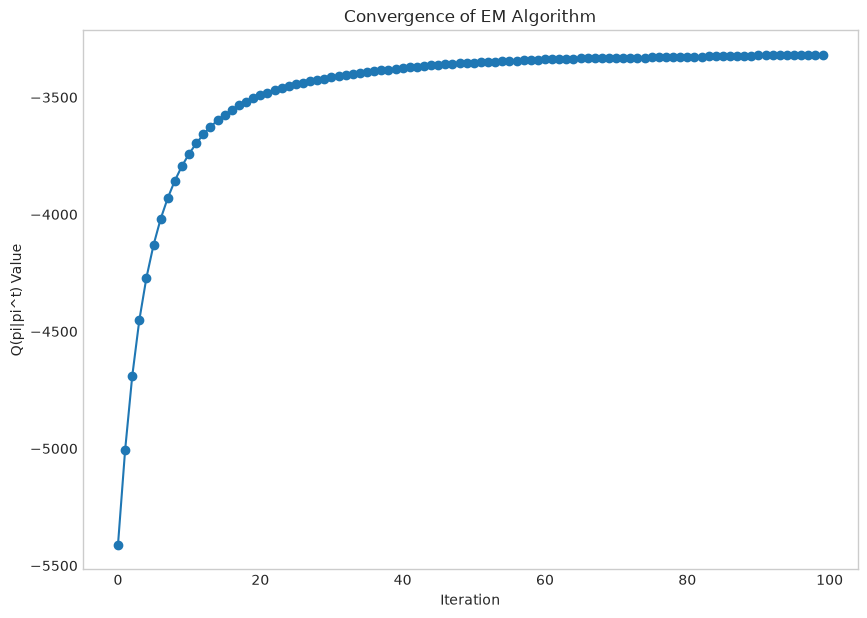

In [11]:
em_visualization(q_function_values)

### Singature composition visualization

In [12]:
totals = expected_counts_per_signature.sum(axis=0)
top_sbs = totals.nlargest(10).index

expected_counts_top_sbs = expected_counts_per_signature.loc[:, top_sbs]

/home/bee/code/mutrate/scr/signature_estimation.py:184: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


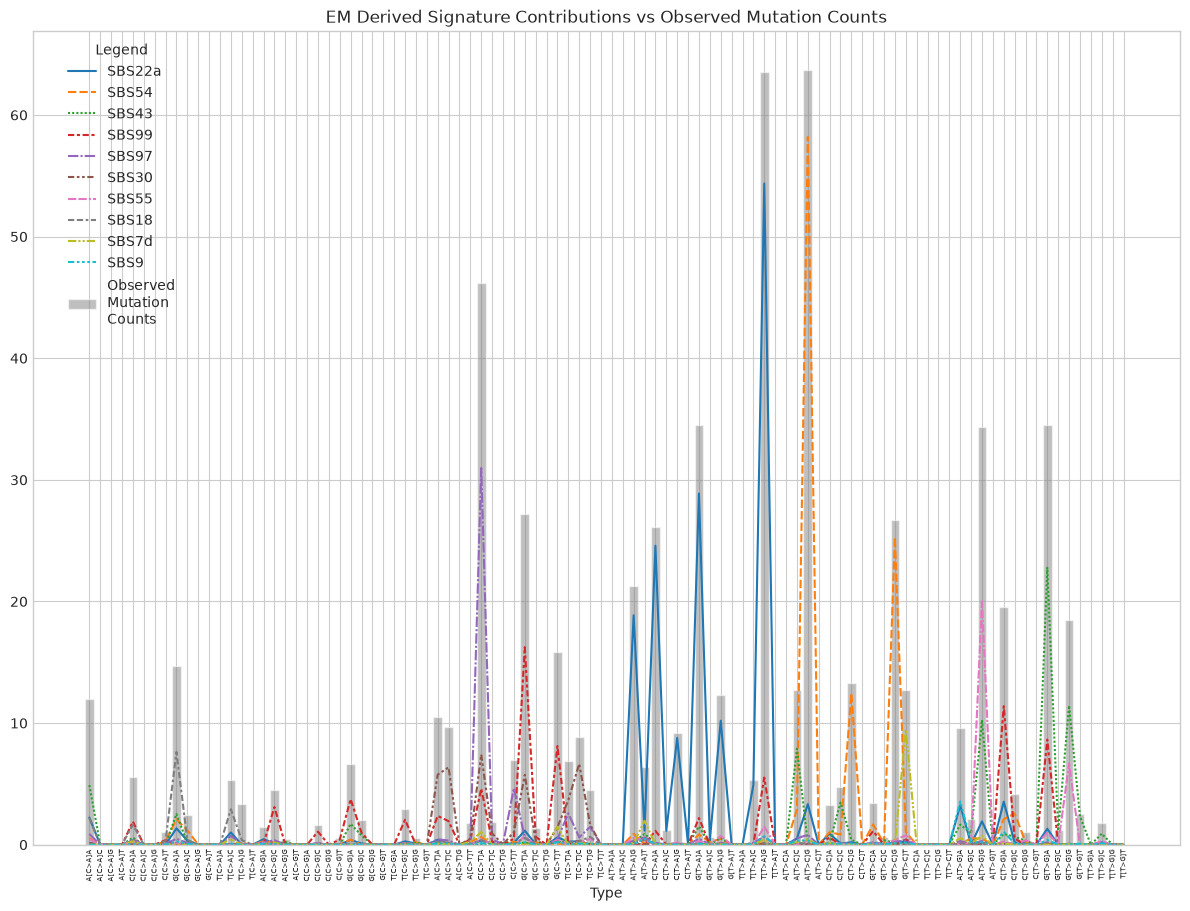

In [13]:
signatures_visualization(expected_counts_per_signature=expected_counts_top_sbs, normalized_matrix=normalized_mutation_df)